# GT2.04–GT2.05 — Autoencodeurs pour le diagnostic de roulements

**Cahier d'expérimentation scientifique — Membre B**

**Question principale :** parmi les modèles classiques et les autoencodeurs étudiés, quelles représentations permettent (1) de regrouper les états de roulements et (2) de distinguer les observations saines des observations défectueuses ?

Ce notebook explique **les hypothèses, les données, les modèles, les choix méthodologiques, les expériences et leurs limites**. Les fonctions de calcul réutilisables restent dans `src/ae_benchmark/` : cette organisation est volontaire pour rendre l'ensemble maintenable et testable.

**Provenance :** `notebook/autoencodeurs_roulements.ipynb` (équipe) a construit `bd_v1.pkl`. Nous n'en remplaçons ni les cellules ni la préparation.

> **Statut scientifique : validation exploratoire uniquement.** Entraînement sur le régime 10, validation sur le régime 20, régime 15 réservé. L'indépendance physique des acquisitions n'est pas démontrée ; **aucun résultat ici ne constitue une validation finale hors fuite d'acquisition**.


## 0. Mode d'emploi et reproductibilité

Depuis la racine du projet, activer `.venv` et installer les dépendances : `python -m pip install -r requirements.txt`, puis `python -m pip install ipykernel`.

Les cellules **lisent par défaut les données et expériences existantes** ; elles ne relancent **pas** les entraînements longs. Les expériences supplémentaires issues des articles ne s'exécutent que si vous activez explicitement le drapeau correspondant.

Fichiers complémentaires :
- `run_benchmark_bd_v1.py` : benchmark général sur les données de l'équipe.
- `run_literature_ablation.py` : étude ciblée **CNN/DAE versus MemAE/ADAE**, avec graines répétées et perturbations spectrales synthétiques.
- `synthese_gt204_gt205.py` : agrégation des résultats déjà calculés.
- `docs/ETUDE_SCIENTIFIQUE_GT204_GT205.md` : justification bibliographique, protocole et limites.


In [1]:
from pathlib import Path
import sys
import subprocess
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

# Le notebook s'ouvre indifféremment depuis la racine ou notebook/.
HERE = Path.cwd().resolve()
candidates = [HERE, *HERE.parents]
ROOT = next((p for p in candidates if (p / "bd_v1.pkl").is_file()
             and (p / "run_benchmark_bd_v1.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Ouvrir le projet contenant bd_v1.pkl et run_benchmark_bd_v1.py")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
RESULTS = ROOT / "results" / "gt204_gt205"
print("Projet :", ROOT)
print("Python :", sys.executable)


Projet : D:\document\3A_ML\Projet-ML-3A
Python : d:\document\3A_ML\Projet-ML-3A\.venv\Scripts\python.exe


## 1. Jeu de données : ce que nous utilisons réellement

Le notebook collectif a extrait **8 431 observations exploitables** de fichiers de vibrations (deux capteurs). Son fichier `bd_v1.pkl` contient un couple `(bd, SPECTRES)` :

- `bd` : états `SAFE`, `BALL`, `INNER_RACE`, `OUTER_RACE`, `COMBINED` ; régimes 10/15/20 ; métadonnées ; **26 descripteurs** statistiques et fréquentiels ;
- `SPECTRES` : **512 valeurs de log-PSD**, soit **256 indices spectraux par capteur**.

**Précaution physique :** les 256 points de chaque canal ne sont **pas** une série temporelle brute. L'axe ci-dessous est donc un **indice spectral**, pas une fréquence validée en Hz. Les étiquettes de régime ne doivent pas être converties arbitrairement en tr/min.


In [2]:
from src.ae_benchmark.collaborative_data import (
    load_collaborative_database, get_split_indices, FEATURE_COLUMNS
)
data = load_collaborative_database(ROOT / "bd_v1.pkl", representation="spectres")
assert data.x.shape[1:] == (2, 256)
print("Forme des spectres :", data.x.shape)
print("Nombre de descripteurs physiques :", len(FEATURE_COLUMNS))
display(pd.crosstab(data.frame["vitesse"], data.frame["classe"], margins=True))


Forme des spectres : (8431, 2, 256)
Nombre de descripteurs physiques : 26


classe,BALL,COMBINED,INNER_RACE,OUTER_RACE,SAFE,All
vitesse,,,,,,
10,566,550,556,527,523,2722
15,576,575,658,562,664,3035
20,555,519,562,515,523,2674
All,1697,1644,1776,1604,1710,8431


### 1.1 Observer les spectres sans confondre visualisation et diagnostic

La représentation spectrale permet de voir si les conditions saines et défectueuses semblent différentes. **Une différence visuelle ne prouve pas** que le modèle généralise, notamment lorsque plusieurs fichiers sont issus d'une même acquisition.


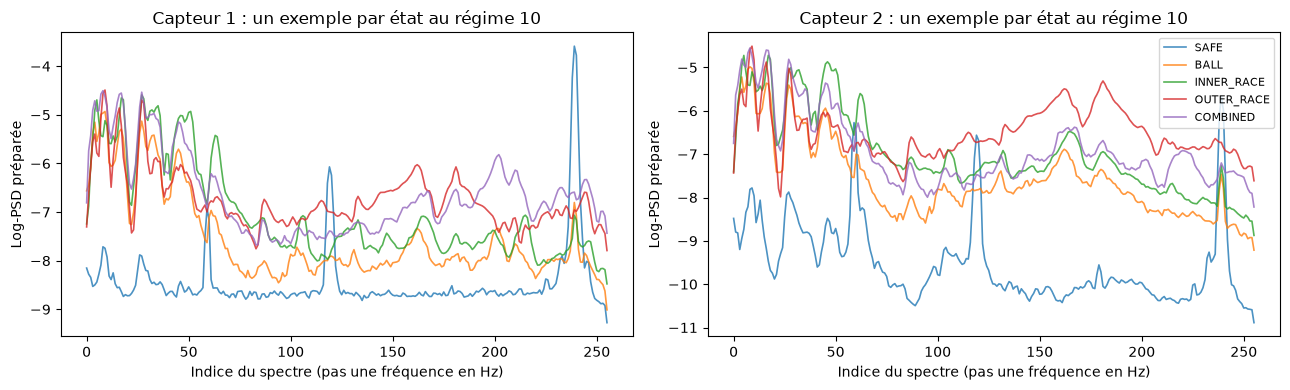

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharex=True)
for channel, ax in enumerate(axes):
    for label in ("SAFE", "BALL", "INNER_RACE", "OUTER_RACE", "COMBINED"):
        indices = np.flatnonzero((data.labels == label) & (data.regimes == "10"))
        if len(indices):
            ax.plot(data.x[indices[0], channel], label=label, alpha=0.8, linewidth=1.2)
    ax.set_title(f"Capteur {channel+1} : un exemple par état au régime 10")
    ax.set_xlabel("Indice du spectre (pas une fréquence en Hz)")
    ax.set_ylabel("Log-PSD préparée")
axes[-1].legend(fontsize=8, loc="best")
plt.tight_layout()
plt.show()


## 2. Protocole de comparaison et prévention des fuites

### 2.1 Pourquoi un nouveau découpage ?

Dans le notebook initial, les fichiers sont répartis individuellement dans `train`, `val` et `test`. Les préfixes des noms suggèrent que des fenêtres voisines peuvent être dispersées dans plusieurs ensembles. Cela crée un **risque de corrélation ou fuite d'acquisition**. On ne peut pas transformer ce soupçon en certitude sans métadonnées physiques.

Pour avancer de façon mieux contrôlée, notre campagne actuelle utilise **des régimes disjoints** :

| Usage | Régime | Observations |
|---|---|---|
| Entraînement | 10 | Toutes les classes en clustering ; seulement SAFE en détection |
| Validation et comparaison | 20 | Mesure des métriques |
| Réservé | 15 | **Aucun choix de modèle ni réglage** |

Ce protocole évalue un **transfert entre régimes**, pas une généralisation garantie entre roulements ou acquisitions indépendants.


In [4]:
train_idx, val_idx, reserved_idx = get_split_indices(
    data, mode="regime", train_regimes="10", val_regime="20", test_regime="15"
)
print("Train / Validation / Réservé :", len(train_idx), len(val_idx), len(reserved_idx))
assert set(data.regimes[train_idx]) == {"10"}
assert set(data.regimes[val_idx]) == {"20"}
assert set(data.regimes[reserved_idx]) == {"15"}
display(pd.crosstab(data.frame.iloc[val_idx]["classe"],
                    data.frame.iloc[val_idx]["vitesse"]))


Train / Validation / Réservé : 2722 2674 3035


vitesse,20
classe,
BALL,555
COMBINED,519
INNER_RACE,562
OUTER_RACE,515
SAFE,523


### 2.2 Vérifier les séries présumées

La commande ci-dessous étudie les préfixes de noms de fichiers. Le résultat est **un indice**, pas une preuve du nombre réel d'essais ou de roulements. Nous n'utiliserons donc pas ces préfixes comme identifiants d'acquisitions indépendantes dans un test final.


In [5]:
series_presumees = data.frame["fichier"].str.replace(r"_\d+\.xlsx$", "", regex=True)
table_series = pd.crosstab(
    [data.frame["classe"], data.frame["vitesse"], series_presumees],
    data.frame["split"]
)
melanges = (table_series.gt(0).sum(axis=1) > 1)
print(f"Séries présumées présentes dans plusieurs splits : {int(melanges.sum())}/{len(table_series)}")
display(table_series.head(8))


Séries présumées présentes dans plusieurs splits : 17/17


split                            test  train  val
classe     vitesse fichier                       
BALL       10      ball_98         85    396   85
           15      ball_148        87    403   86
           20      ball_197        83    389   83
COMBINED   10      combined_97     82    385   83
           15      combined_147    87    402   86
           20      combined_197    78    363   78
INNER_RACE 10      inner_97        84    389   83
           15      inner_147       98    461   99

### 2.3 Normalisation sans information de validation

Le centrage et la réduction sont ajustés sur le **train uniquement**. Pour le clustering, le train inclut toutes les classes. Pour la détection, le modèle n'apprend que sur les observations `SAFE` du régime 10.

Les étiquettes des défauts ne sont pas utilisées pour entraîner les autoencodeurs de détection ; elles servent uniquement aux métriques d'évaluation.


In [6]:
from sklearn.preprocessing import StandardScaler
idx_safe_train = train_idx[data.labels[train_idx] == "SAFE"]
scaler_demo = StandardScaler().fit(data.x[idx_safe_train].reshape(len(idx_safe_train), -1))
x_scaled = scaler_demo.transform(data.x.reshape(len(data.x), -1)).reshape(data.x.shape)
print("Observations SAFE utilisées pour apprendre la normalisation :", len(idx_safe_train))
print("Moyenne train SAFE normalisé :", round(float(x_scaled[idx_safe_train].mean()), 6))


Observations SAFE utilisées pour apprendre la normalisation : 523
Moyenne train SAFE normalisé : 0.0


## 3. Architectures étudiées : principe et implémentation

Un **autoencodeur (AE)** produit une représentation latente \(z=f_\theta(x)\), puis une reconstruction \(\hat{x}=g_\phi(z)\). Un entraînement classique minimise l'erreur quadratique de reconstruction :

\[
\mathcal L_{\mathrm{rec}}=\frac{1}{N}\sum_{i=1}^{N}\left\|x_i-\hat{x}_i\right\|_2^2.
\]

Les variantes testées sont :

| Architecture | Idée mise à l'épreuve | Module |
|---|---|---|
| MLP-AE | Compression dense des log-spectres | `models.py` |
| CNN-AE | Extraction de motifs locaux le long des indices spectraux | `models.py` |
| Denoising CNN-AE | Reconstruction de l'entrée propre à partir d'une entrée bruitée | `models.py` |
| VAE convolutionnel | Régulariser les représentations latentes par une distribution | `models.py` |
| IDEC | Raffiner les affectations de clusters tout en conservant la reconstruction | `deep_clustering.py` |

La **présence d'un modèle dans le code ne signifie pas qu'il a été validé sur données réelles**.


In [7]:
from src.ae_benchmark.models import build_model
modeles_inspectes = ("mlp", "cnn", "denoise", "vae", "memae", "adae")
inventaire = []
for nom in modeles_inspectes:
    modele = build_model(nom, length=256, channels=2, latent_dim=6)
    inventaire.append({
        "modele": nom,
        "parametres_entrainables": sum(p.numel() for p in modele.parameters() if p.requires_grad),
        "representation_entree": "(N,2,256)"
    })
display(pd.DataFrame(inventaire))


,modele,parametres_entrainables,representation_entree
0,mlp,296838,"(N,2,256)"
1,cnn,80680,"(N,2,256)"
2,denoise,80680,"(N,2,256)"
3,vae,85294,"(N,2,256)"
4,memae,80872,"(N,2,256)"
5,adae,45624,"(N,2,256)"


### 3.1 VAE et IDEC : les équations qui justifient nos expériences

Dans notre VAE, le code applique une reconstruction MSE et une pénalité KL pondérée, avec \(\beta = 0{,}001\) dans la configuration par défaut :

\[
\mathcal L_{VAE}=\mathbb E[\|x-\hat x\|^2]+\beta D_{KL}\left(q_\theta(z\mid x)\Vert\mathcal N(0,I)\right).
\]

L'encodeur fournit une moyenne latente (utilisée de façon déterministe pour K-Means) et une variance pour l'échantillonnage pendant l'apprentissage.

**IDEC** combine une perte de reconstruction et une divergence KL entre affectations latentes et cibles affûtées :

\[
\mathcal L_{IDEC}=\mathcal L_{rec}+\gamma D_{KL}(P\Vert Q).
\]

Notre \(`idec(vae)`\) est une **adaptation expérimentale** de [Guo et al. (IJCAI 2017)](https://www.ijcai.org/proceedings/2017/243) : le raffinement IDEC réutilise le VAE préentraîné, mais ne réoptimise pas pendant cette phase l'objectif variationnel complet du VAE. **Ce n'est pas une reproduction stricte de l'article.**


## 4. GT2.04 — Campagne de clustering sur le régime 20

**Clustering non supervisé :** le réseau apprend sans employer les étiquettes de défaut ; K-Means regroupe les codes latents. Les étiquettes sont utilisées **après prédiction** pour calculer ARI et NMI.

- **ARI** (Adjusted Rand Index) : accord des partitions, corrigé pour le hasard ; plus grand est préférable.
- **NMI** (Normalized Mutual Information) : information partagée entre labels réels et clusters.
- **Silhouette** : compacité et séparation géométrique des groupes sans labels ; elle peut augmenter même si l'ARI diminue.

Il faut comparer K-Means direct, PCA + K-Means, puis AE + K-Means, **avec le même découpage**. Les résultats de test du notebook collectif ne sont pas directement comparables à la validation inter-régimes ci-dessous.


In [8]:
SYNTH = RESULTS / "synthese"
ARCHIVE = ROOT / "reports" / "gt204_gt205"
fichiers_locaux = [
    "clustering_cinq_graines.csv",
    "clustering_statistiques.csv",
    "clustering_une_execution.csv",
    "detection_corrigee.csv",
]
SORTIES_LOCALES_COMPLETES = all((SYNTH / name).is_file() for name in fichiers_locaux)

if SORTIES_LOCALES_COMPLETES:
    print("Source : résultats originaux générés localement par les scripts.")
    cinq_graines = pd.read_csv(SYNTH / "clustering_cinq_graines.csv")
    stats = pd.read_csv(SYNTH / "clustering_statistiques.csv")
    comparaison = pd.read_csv(SYNTH / "clustering_une_execution.csv")
    detection = pd.read_csv(SYNTH / "detection_corrigee.csv")
else:
    print("Source : archives versionnées transcrites des sorties PowerShell.")
    print("Provenance :", ARCHIVE / "PROVENANCE.md")
    cinq_graines = pd.read_csv(ARCHIVE / "clustering_cinq_graines.csv")
    comparaison = pd.read_csv(ARCHIVE / "clustering_comparaison_initiale.csv")
    detection = pd.read_csv(ARCHIVE / "detection_validation_corrigee.csv")
    stats = (cinq_graines.groupby("model")[["ARI", "NMI", "silhouette"]]
             .agg(["mean", "std", "min", "max"]))
    stats.columns = ["_".join(metric) for metric in stats.columns]
    stats = stats.reset_index()

print("Comparaison exploratoire : une exécution des architectures")
display(comparaison[["model", "ARI", "NMI", "silhouette"]]
        .sort_values("ARI", ascending=False))


Source : résultats originaux générés localement par les scripts.
Comparaison exploratoire : une exécution des architectures


,model,ARI,NMI,silhouette
0,spectra+kmeans,0.609269,0.782830,0.257559
1,pca+kmeans,0.609269,0.782830,0.267101
5,vae,0.554352,0.737333,0.444081
2,mlp,0.469283,0.730539,0.236037
3,cnn,0.460992,0.689051,0.279546
4,denoise,0.460276,0.670750,0.224381


### 4.1 Stabilité : ne pas sélectionner une graine favorable après coup

Le VAE et `idec(vae)` ont été entraînés avec **cinq initialisations : 0, 1, 7, 21, 42**. Nous rapportons la moyenne et l'écart-type **échantillon** (ddof = 1), ainsi que les valeurs individuelles. Ces répétitions portent sur les poids et l'ordre de l'apprentissage, **pas sur cinq nouvelles acquisitions indépendantes**.


Résultats par graine :


,seed,model,ARI,NMI,silhouette
0,0,idec(vae),0.685492,0.811120,0.518631
1,1,idec(vae),0.627791,0.789278,0.364904
2,7,idec(vae),0.606496,0.773696,0.302025
3,21,idec(vae),0.742310,0.861993,0.431028
4,42,idec(vae),0.609396,0.782894,0.208954
5,0,vae,0.769964,0.889452,0.607022
6,1,vae,0.762304,0.880528,0.554581
7,7,vae,0.767793,0.886629,0.550760
8,21,vae,0.704955,0.811095,0.518999
9,42,vae,0.554443,0.721790,0.295773


Statistiques descriptives (écart-type échantillon) :


,model,ARI_mean,ARI_std,NMI_mean,NMI_std,silhouette_mean,silhouette_std
0,idec(vae),0.654297,0.058573,0.803796,0.035335,0.365108,0.118615
1,vae,0.711892,0.092028,0.837899,0.072542,0.505427,0.121379


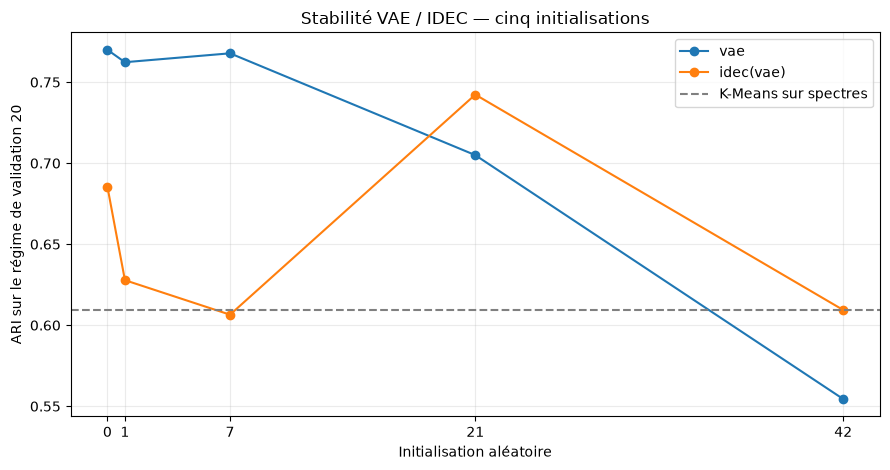

In [9]:
print("Résultats par graine :")
display(cinq_graines.sort_values(["model", "seed"]))
print("Statistiques descriptives (écart-type échantillon) :")
display(stats[["model", "ARI_mean", "ARI_std", "NMI_mean", "NMI_std",
               "silhouette_mean", "silhouette_std"]])

fig, ax = plt.subplots(figsize=(9, 4.8))
for modele in ("vae", "idec(vae)"):
    series = cinq_graines.loc[cinq_graines["model"] == modele].sort_values("seed")
    ax.plot(series["seed"], series["ARI"], marker="o", label=modele)
baseline = float(comparaison.loc[comparaison["model"] == "spectra+kmeans", "ARI"].iloc[0])
ax.axhline(baseline, linestyle="--", color="gray", label="K-Means sur spectres")
ax.set_xticks(sorted(cinq_graines["seed"].unique()))
ax.set_xlabel("Initialisation aléatoire")
ax.set_ylabel("ARI sur le régime de validation 20")
ax.set_title("Stabilité VAE / IDEC — cinq initialisations")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()


### 4.2 Lecture critique

Dans cette campagne, VAE + K-Means a un ARI moyen d'environ **0,712 ± 0,092** ; IDEC environ **0,654 ± 0,059** ; K-Means sur spectres atteint **0,609** (même protocole, une référence). IDEC **n'améliore pas systématiquement** le VAE.

Ces valeurs constituent une **présélection**. Cinq graines sont insuffisantes pour une preuve statistique de supériorité industrielle, et seule la validation au régime 20 a été consultée.


### 4.3 Contrôle des courbes d'apprentissage

Le script général conserve `train_loss` et `validation_mse` pour chaque époque. La meilleure époque est choisie sur l'erreur de reconstruction de validation (et non sur les étiquettes du défaut).

Comparer les deux courbes aide à détecter une stagnation ou un surapprentissage. Pour le **VAE**, `train_loss` combine reconstruction et divergence KL, tandis que `validation_mse` mesure uniquement la reconstruction : leurs ordonnées ne représentent donc **pas exactement la même fonction objectif**.


,epoch,train_loss,validation_mse
10,11,0.040547,0.346974
11,12,0.038741,0.341430
12,13,0.036884,0.361766
13,14,0.035316,0.356283
14,15,0.035613,0.366763


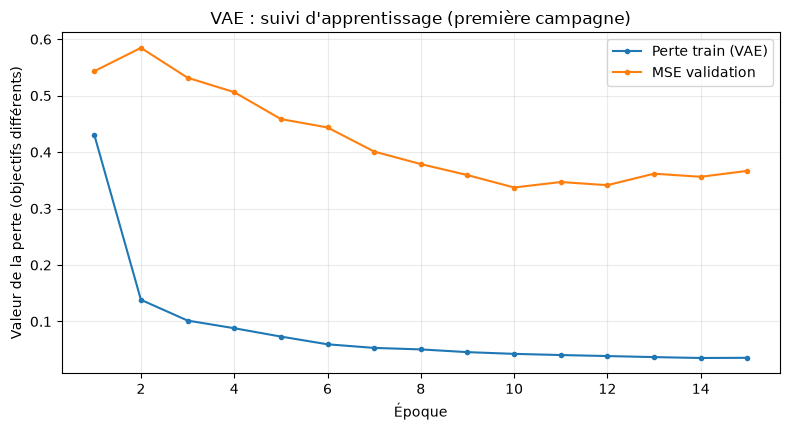

In [10]:
historique = RESULTS / "comparaison_approfondie" / "clustering_vae_training.csv"
if historique.is_file():
    courbes = pd.read_csv(historique)
    display(courbes.tail(5))
    fig, ax = plt.subplots(figsize=(8, 4.4))
    ax.plot(courbes["epoch"], courbes["train_loss"], marker=".", label="Perte train (VAE)")
    ax.plot(courbes["epoch"], courbes["validation_mse"], marker=".", label="MSE validation")
    ax.set_xlabel("Époque")
    ax.set_ylabel("Valeur de la perte (objectifs différents)")
    ax.set_title("VAE : suivi d'apprentissage (première campagne)")
    ax.legend()
    ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()
else:
    print("Historique local non disponible ; voir le fichier CSV généré par le benchmark.")


## 5. GT2.04 — Campagne de détection d'anomalies

**Hypothèse :** entraîné sur les spectres `SAFE`, un modèle reconstruit normalement mieux ces observations que les spectres défectueux.

Pour les autoencodeurs, le score est l'erreur quadratique \(s(x)=\mathrm{MSE}(x,\hat x)\). Un **seuil** \(\tau\) est fixé au quantile 99 % des scores d'un **sous-ensemble SAFE de calibration distinct**. Une observation est déclarée anormale si \(s(x)>\tau\).

Dans notre screening corrigé, les SAFE de validation sont séparés en trois groupes **disjoints** : choix de l'époque, calibration du seuil, mesure des fausses alarmes. Tous les défauts de validation sont réservés à l'évaluation. Cette mesure ne prouve pas encore une validation sur acquisition indépendante.

**Métriques :** AUROC et AUPRC (sans seuil), rappel, précision, F1 et taux de fausses alarmes (au seuil choisi). La validation comporte une **forte prévalence artificielle de défauts** ; F1 et précision en dépendent.


,model,AUROC,average_precision,precision,recall,F1,false_alarm_rate,threshold
1,isolation_forest,1.0,1.0,0.998607,1.0,0.999303,0.017143,0.722053
5,vae,1.0,1.0,0.998607,1.0,0.999303,0.017143,155.816742
4,denoise,1.0,1.0,0.997218,1.0,0.998607,0.034286,173.741531
0,pca,1.0,1.0,0.996756,1.0,0.998375,0.040000,235.357285
3,cnn,1.0,1.0,0.996295,1.0,0.998144,0.045714,164.548462
2,mlp,1.0,1.0,0.996295,1.0,0.998144,0.045714,242.319962


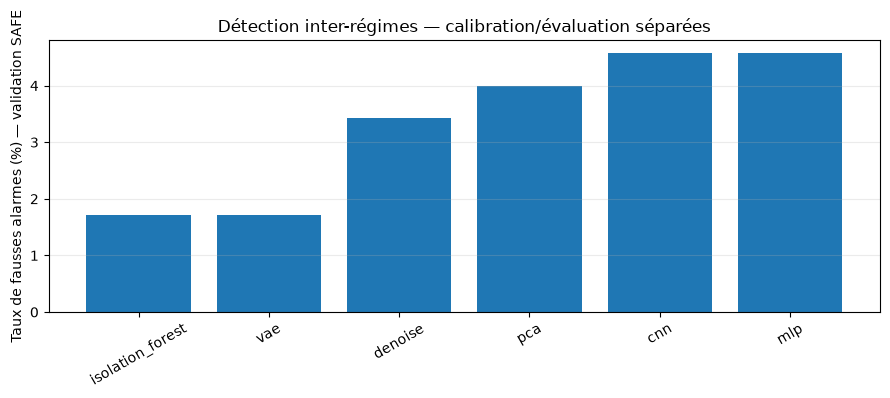

In [11]:
display(detection[["model", "AUROC", "average_precision", "precision",
                    "recall", "F1", "false_alarm_rate", "threshold"]]
        .sort_values("false_alarm_rate"))

fig, ax = plt.subplots(figsize=(9, 4))
ordre = detection.sort_values("false_alarm_rate")
ax.bar(ordre["model"], 100 * ordre["false_alarm_rate"])
ax.set_ylabel("Taux de fausses alarmes (%) — validation SAFE")
ax.set_title("Détection inter-régimes — calibration/évaluation séparées")
ax.grid(axis="y", alpha=0.25)
ax.tick_params(axis="x", labelrotation=30)
plt.tight_layout()
plt.show()


### 5.1 Une AUROC parfaite ne suffit pas

Sur ce screening, tous les modèles ont AUROC = 1,000. Pourtant, leurs **fausses alarmes** ne sont pas identiques. VAE et Isolation Forest atteignent chacun **3 fausses alarmes parmi 175 SAFE évalués**, soit environ 1,71 %, avec rappel de 100 % parmi les défauts évalués.

Une AUROC de 1,000 sur ces données ne prouve **pas** que le diagnostic sera parfait sur une autre acquisition, un autre roulement ou un autre site industriel. Elle invite à analyser le protocole et le nombre d'exemples.


## 6. Exploitation des articles : hypothèses nouvelles et vérifiables

Nous distinguons trois niveaux : **(a) article consulté**, **(b) adaptation implémentée**, **(c) expérience exécutée sur les données réelles**.

### 6.1 [Gong et al., ICCV 2019 — MemAE](https://openaccess.thecvf.com/content_ICCV_2019/html/Gong_Memorizing_Normality_to_Detect_Anomaly_Memory-Augmented_Deep_Autoencoder_for_Unsupervised_ICCV_2019_paper.html)

**Idée :** un AE classique peut parfois reconstruire trop bien des défauts. MemAE incorpore une mémoire des motifs normaux et limite la reconstruction à quelques prototypes pertinents.

**Notre adaptation :** `SparseMemAE` dans `advanced_models.py`, avec mémoire apprenable, lecture **top-k** et pénalité d'entropie ; le mécanisme **n'est pas le hard-shrinkage exact de l'article**.

**Hypothèse H1 :** à budget d'apprentissage comparable, `memae` réduit le taux de fausses alarmes ou améliore le rappel par rapport à `cnn`, sans sélectionner la meilleure graine.

### 6.2 [Lu, Zhou & He, Electronics 2024 — ADAE](https://doi.org/10.3390/electronics13122403)

**Idée :** unités de rétrécissement adaptatif, régularisation, connexions résiduelles et reconstruction débruitée pour atténuer le bruit qui masque les défauts.

**Notre adaptation :** `AdaptiveDenoisingAE` inclut des portes multiplicatives, résidus, dropout et perte SmoothL1. Ce n'est pas l'architecture identique de la publication.

**Hypothèse H2 :** `adae` présente un meilleur compromis rappel / fausses alarmes que le débruiteur CNN `denoise` sous perturbation des spectres.

### 6.3 [Lu et al., IEEE TIM 2025 — CMAE](https://doi.org/10.1109/TIM.2025.3546365)

Le papier associe mémoire en cascade et suivi d'ordres angulaires pour des régimes variables. Notre prototype `cmae` n'implémente **pas** le suivi d'ordres : il n'est donc qu'une **ablation facultative sur spectres**, pas une validation de la méthode complète.


### 6.4 Conception de l'ablation

Pour comparer les idées plutôt que des valeurs prises au hasard :

1. Utiliser exactement les mêmes **régimes, spectres et partitions SAFE** pour toutes les architectures.
2. Réinitialiser la graine **avant chaque construction de réseau** (éviter l'effet d'ordre du benchmark multi-modèles initial).
3. Choisir l'époque uniquement sur SAFE de validation, le seuil sur un autre groupe SAFE, puis évaluer sur les autres SAFE et les défauts.
4. Répéter sur plusieurs graines ; enregistrer **toutes** les métriques, les courbes et la configuration.
5. Évaluer **en plus** une perturbation gaussienne additive contrôlée **sur le log-spectre standardisé**. Ce test est une sensibilité numérique, **pas** une simulation physique validée de bruit de capteur : il ne démontre pas un débruitage vibratoire réel.

Le script `run_literature_ablation.py` a été exécuté le 03/11/2026 sur les données préparées par l'équipe. **Ces résultats sont des validations inter-régimes exploratoires, pas des performances industrielles sur acquisitions indépendantes.**


In [12]:
# Contrôle des paramètres du nouveau protocole, sans lancer de calcul lourd.
from run_literature_ablation import validate_args, parse_args
from argparse import Namespace

config_ablation = Namespace(
    models="cnn,denoise,memae,adae", seeds="0,7,21",
    epochs=15, batch_size=64, latent_dim=6,
    noise_levels="0,0.15,0.30", device="cpu"
)
print("Modèles, graines, niveaux de perturbation, calcul :")
print(validate_args(config_ablation))


Modèles, graines, niveaux de perturbation, calcul :
(['cnn', 'denoise', 'memae', 'adae'], [0, 7, 21], [0.0, 0.15, 0.3], 'cpu')


### 6.5 Lancer l'ablation de façon contrôlée

**Contrôle technique déjà exécuté avec succès**, depuis PowerShell (une graine et deux époques) :

```powershell
python -m pytest -q
python run_literature_ablation.py --models cnn,denoise,memae,adae --seeds 0 --epochs 2 --noise-levels 0,0.15 --out results/gt204_gt205/ablation_articles_smoke
```

**Campagne complète exécutée avec succès le 03/11/2026** (15 époques, trois graines, sans toucher au régime 15) :

```powershell
python run_literature_ablation.py --models cnn,denoise,memae,adae --seeds 0,7,21 --epochs 15 --noise-levels 0,0.15,0.30 --out results/gt204_gt205/ablation_articles
```

**Ces commandes sont fournies pour la reproduction : elles n'ont pas besoin d'être relancées. Aucune n'est exécutée automatiquement** lorsque l'on clique sur *Run All*.


In [13]:
LANCER_ABLATION_DEPUIS_NOTEBOOK = False  # Mettre True seulement après avoir choisi le budget.
if LANCER_ABLATION_DEPUIS_NOTEBOOK:
    cmd = [sys.executable, str(ROOT / "run_literature_ablation.py"),
           "--models", "cnn,denoise,memae,adae",
           "--seeds", "0,7,21", "--epochs", "15",
           "--noise-levels", "0,0.15,0.30",
           "--out", str(RESULTS / "ablation_articles")]
    subprocess.run(cmd, cwd=str(ROOT), check=True)
else:
    print("Entraînement des modèles tirés des articles désactivé par défaut.")


Entraînement des modèles tirés des articles désactivé par défaut.


### 6.6 Résultats réels : comparaison des articles après trois initialisations

La campagne **a été exécutée le 03/11/2026**, avec les modèles `cnn,denoise,memae,adae`, trois graines `0,7,21`, 15 époques et les perturbations standardisées `0,0.15,0.30`. Les tableaux locaux contiennent les scores individuels et par classe ; une **archive versionnée des moyennes rapportées dans PowerShell** se trouve dans `reports/gt204_gt205/ablation_articles_moyennes_console.csv`.

Les observations montrent qu'**aucune architecture inspirée de MemAE ou ADAE ne domine clairement CNN-AE sur spectres non perturbés**. Les performances très élevées invitent à contrôler les sources de corrélations entre fenêtres et à éviter toute généralisation excessive. Les trois graines réutilisent les mêmes données physiques et ne constituent pas des expériences indépendantes.

**Attention :** les perturbations sont ajoutées aux log-PSD standardisées ; elles ne représentent pas une mesure physique de la robustesse au bruit vibratoire réel.


In [14]:
ABLA = RESULTS / "ablation_articles"
AGREGATS_ARCHIVE = ARCHIVE / "ablation_articles_moyennes_console.csv"
if (ABLA / "resultats_par_graine_et_bruit.csv").is_file():
    individuelles = pd.read_csv(ABLA / "resultats_par_graine_et_bruit.csv")
    print("Scores réels individuels sur trois graines, sans perturbation :")
    display(individuelles.loc[individuelles.noise_std == 0,
        ["seed", "model", "AUROC", "F1", "false_alarm_rate", "recall", "train_seconds"]]
        .sort_values(["model", "seed"]))
    print("Source : CSV bruts du PC.")
    resume_articles = pd.read_csv(ABLA / "synthese_moyennes.csv")
else:
    print("Source : archive versionnée des moyennes affichées dans PowerShell.")
    raw_archive = ARCHIVE / "ablation_articles_par_graine.csv"
    if raw_archive.is_file():
        individuelles = pd.read_csv(raw_archive)
        print("Archive des trois graines :")
        display(individuelles.loc[individuelles.noise_std == 0,
            ["seed", "model", "AUROC", "F1", "false_alarm_rate", "recall"]]
            .sort_values(["model", "seed"]))
    else:
        print("Pour publier les résultats individuels, copier les CSV locaux dans reports/gt204_gt205/.")
    resume_articles = pd.read_csv(AGREGATS_ARCHIVE)

colonnes = ["model","noise_std","AUROC_mean","F1_mean",
            "F1_std","false_alarm_rate_mean","false_alarm_rate_std","recall_mean"]
display(resume_articles[colonnes].sort_values(["noise_std","false_alarm_rate_mean"]))

fig, ax = plt.subplots(figsize=(9,4.4))
for name, series in resume_articles.groupby("model"):
    series=series.sort_values("noise_std")
    ax.plot(series.noise_std, 100*series.false_alarm_rate_mean,
            marker="o", label=name)
ax.set_xlabel("Perturbation additive sur log-PSD standardisées (σ)")
ax.set_ylabel("Taux moyen de fausses alarmes (%)")
ax.set_title("Sensibilité numérique des détecteurs : trois graines, validation régime 20")
ax.grid(alpha=0.25)
ax.legend(ncol=2)
plt.tight_layout()
plt.show()


Scores réels individuels sur trois graines, sans perturbation :


,seed,model,AUROC,F1,false_alarm_rate,recall,train_seconds
9,0,adae,1.000000,1.000000,0.000000,1.000000,5.730
24,7,adae,1.000000,0.999071,0.022857,1.000000,6.034
39,21,adae,1.000000,0.999768,0.005714,1.000000,6.125
0,0,cnn,1.000000,0.999535,0.011429,1.000000,7.902
15,7,cnn,1.000000,0.999768,0.005714,1.000000,6.109
30,21,cnn,1.000000,1.000000,0.000000,1.000000,5.804
3,0,denoise,1.000000,0.999303,0.017143,1.000000,5.123
18,7,denoise,1.000000,0.999071,0.022857,1.000000,6.133
33,21,denoise,1.000000,1.000000,0.000000,1.000000,5.941
12,0,isolation_forest,1.000000,0.999303,0.017143,1.000000,0.320


Source : CSV bruts du PC.


,model,noise_std,AUROC_mean,F1_mean,F1_std,false_alarm_rate_mean,false_alarm_rate_std,recall_mean
3,cnn,0.00,1.000000,0.999768,0.000232,0.005714,0.005714,1.000000
12,memae,0.00,1.000000,0.999690,0.000268,0.007619,0.006598,1.000000
0,adae,0.00,1.000000,0.999613,0.000483,0.009524,0.011895,1.000000
6,denoise,0.00,1.000000,0.999458,0.000483,0.013333,0.011895,1.000000
9,isolation_forest,0.00,0.999363,0.998992,0.000538,0.013333,0.006598,0.999070
4,cnn,0.15,1.000000,0.999768,0.000232,0.005714,0.005714,1.000000
13,memae,0.15,1.000000,0.999690,0.000268,0.007619,0.006598,1.000000
1,adae,0.15,1.000000,0.999613,0.000483,0.009524,0.011895,1.000000
7,denoise,0.15,1.000000,0.999458,0.000483,0.013333,0.011895,1.000000
10,isolation_forest,0.15,0.998721,0.998992,0.000748,0.013333,0.003299,0.999070


C:\Users\ahmad\AppData\Local\Temp\ipykernel_3964\587774370.py:39: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


### 6.7 Interprétation de la nouvelle campagne

- **Sans perturbation**, CNN-AE a le taux de fausses alarmes moyen le plus bas parmi les modèles répétés trois fois : **0,5714 %**, suivi par MemAE (**0,7619 %**) et ADAE (**0,9524 %**). Les écarts absolus ne dépassent que quelques alarmes, sur un échantillon SAFE réduit.
- **À σ = 0,30**, MemAE reste à **0,7619 %** et ADAE à **0,9524 %**, tandis que CNN-AE passe à **0,9524 %** ; cela décrit une sensibilité au bruit **numérique dans les spectres**, pas une robustesse industrielle établie.
- Les autoencodeurs ont tous une **AUROC moyenne de 1,0** sur cette validation ; ce score saturé ne les départage pas.
- MemAE ne prouve pas ici la supériorité de la mémoire top-k sur CNN ; ADAE ne prouve pas qu'une unité de rétrécissement adaptatif est seule responsable de la performance.
- Les écarts-types entre graines mesurent une variabilité d'exécution et de partition SAFE, **pas une incertitude sur de nouveaux roulements indépendants**.


## 7. GT2.05 — Présélection argumentée après toutes les campagnes

**Clustering : VAE + K-Means**, ARI moyen **0,7119 ± 0,0920** sur cinq graines. IDEC n'apporte pas un gain systématique ; conserver K-Means classique comme référence.

**Détection : CNN-AE comme candidat principal de validation**, car son taux de fausses alarmes moyen est le plus faible (**0,5714 %**) parmi les détecteurs répétés sous le même protocole sur trois graines. **MemAE** reste une alternative intéressante, notamment sur la perturbation synthétique standardisée. **Isolation Forest** est conservé comme baseline. **VAE détection n'est pas éliminé** : ses résultats antérieurs sur une graine ne sont pas directement comparables à ceux obtenus sur trois graines.

**Pourquoi ne pas déclarer le choix définitif ?** Trois graines ne sont pas trois acquisitions nouvelles ; les fenêtres ont potentiellement une origine commune ; l'AUROC est saturée et les différences correspondent à quelques erreurs sur le sous-ensemble sain. Les résultats doivent être validés sur des acquisitions physiquement indépendantes.

**Pour rendre compte de GT2.05 :** `docs/DECISION_GT205_VALIDATION.md` contient la décision, les chiffres, les références scientifiques, les limitations et les conditions du test final.

**Ce qu'il reste pour une évaluation finale :** identifier de vraies acquisitions indépendantes ; figer les modèles et seuils ; exploiter une seule fois un jeu de test tenu à l'écart ; documenter les écarts de régime, de machine et les coûts de calcul.


In [15]:
# Traçabilité : la synthèse locale est prioritaire, archives de lecture sinon.
sources = [
    ("Archives numériques", ARCHIVE / "PROVENANCE.md"),
    ("Tableau par graine", (SYNTH / "clustering_cinq_graines.csv")
        if SORTIES_LOCALES_COMPLETES else (ARCHIVE / "clustering_cinq_graines.csv")),
    ("Clustering initial", (SYNTH / "clustering_une_execution.csv")
        if SORTIES_LOCALES_COMPLETES else (ARCHIVE / "clustering_comparaison_initiale.csv")),
    ("Détection corrigée", (SYNTH / "detection_corrigee.csv")
        if SORTIES_LOCALES_COMPLETES else (ARCHIVE / "detection_validation_corrigee.csv")),
    ("Nouvelle ablation MemAE/ADAE", ABLA / "protocole.json"),
]
display(pd.DataFrame([
    {"document": label, "present": file.is_file(),
     "chemin": str(file.relative_to(ROOT))}
    for label, file in sources
]))


,document,present,chemin
0,Archives numériques,True,reports\gt204_gt205\PROVENANCE.md
1,Tableau par graine,True,results\gt204_gt205\synthese\clustering_cinq_g...
2,Clustering initial,True,results\gt204_gt205\synthese\clustering_une_ex...
3,Détection corrigée,True,results\gt204_gt205\synthese\detection_corrige...
4,Nouvelle ablation MemAE/ADAE,True,results\gt204_gt205\ablation_articles\protocol...


## 8. Références scientifiques vérifiables

1. **Guo, X., Gao, L., Liu, X., & Yin, J. (2017)**. *Improved Deep Embedded Clustering with Local Structure Preservation*. IJCAI-17, 1753–1759. [DOI 10.24963/ijcai.2017/243](https://doi.org/10.24963/ijcai.2017/243). Idée exploitée : KL des assignations + reconstruction.
2. **Gong, D., et al. (2019)**. *Memorizing Normality to Detect Anomaly: Memory-Augmented Deep Autoencoder for Unsupervised Anomaly Detection*. ICCV, 1705–1714. [Publication en accès libre](https://openaccess.thecvf.com/content_ICCV_2019/html/Gong_Memorizing_Normality_to_Detect_Anomaly_Memory-Augmented_Deep_Autoencoder_for_Unsupervised_ICCV_2019_paper.html). Idée exploitée : mémoire des motifs normaux.
3. **Lu, H., Zhou, K., & He, L. (2024)**. *Bearing Fault Vibration Signal Denoising Based on Adaptive Denoising Autoencoder*. *Electronics*, 13(12), 2403. [DOI 10.3390/electronics13122403](https://doi.org/10.3390/electronics13122403). Idée : débruitage adaptatif.
4. **Lu et al. (2025)**. *Variable Speed Bearing Anomaly Detection via Order Tracking and Cascaded Memory-Augmented Autoencoder*. *IEEE Transactions on Instrumentation and Measurement*. [DOI 10.1109/TIM.2025.3546365](https://doi.org/10.1109/TIM.2025.3546365). Adaptation mémoire seulement, **sans suivi d'ordres**.

Nous **ne reproduisons ni les jeux de données ni les performances publiées** dans ces articles. Le code et nos adaptations sont explicités dans `docs/TRAÇABILITE_ARTICLES_V2.md` et `docs/ETUDE_SCIENTIFIQUE_GT204_GT205.md`.

**Conclusion :** notebook de travail GT2.04 et GT2.05 documenté, résultats de validation archivés, sélection encore provisoire. La branche collective `main` n'est pas modifiée.
